# Classificação de ocorrências em São Paulo: **roubo ou furto?** — MLP

**Global Solution — Aprendizado Profundo com Redes Neurais Convolucionais**
Segurança pública inteligente em São Paulo · classificação de ocorrências com MLP

**Integrantes:** João Carmo Cassu de Castro (RM 567030) · Luiz Gustavo de Almeida (RM 566613)

### Objetivo
Construir, treinar, comparar e selecionar uma **Multilayer Perceptron (MLP)** que, a partir das características de uma
ocorrência **já registrada ou hipotética** de subtração de celular na capital paulista, estime se ela é mais compatível
com **roubo** (art. 157, com violência ou grave ameaça) ou com **furto** (art. 155, sem violência).

> ⚠️ O modelo **não prevê se um crime vai acontecer** nem calcula risco de um lugar/horário.
> Ele responde: *"dado que uma subtração de celular aconteceu com estas características, ela se parece mais com roubo ou com furto?"*

### Roteiro do notebook
1. Fonte dos dados e recorte
2. Exploração da base
3. Pré-processamento (agrupamento, codificação, escalonamento e divisão treino/validação/teste)
4. Implementação da MLP e configuração do treinamento
5. Experimentos com 4 arquiteturas
6. Comparação (acurácia, precision, recall, F1) e seleção pela **validação**
7. Avaliação final no **teste**: matriz de confusão, curvas e análise de overfitting/underfitting
8. Exportação do modelo para a aplicação web
9. Conclusões e limitações

## 1. Fonte dos dados e recorte

| Item | Escolha da equipe |
|---|---|
| **Fonte** | Secretaria da Segurança Pública de SP (SSP-SP) — Portal de Estatísticas → Consultas → *Bases de Dados* → **Celulares subtraídos — 2025**: <https://www.ssp.sp.gov.br/estatistica/consultas> |
| **Arquivo** | `CelularesSubtraidos_2025.xlsx` (≈108 MB, 383.635 linhas, 55 colunas) — baixado em 15/11/2026 |
| **Período** | Fatos ocorridos em **2025** (`DATA_OCORRENCIA_BO`) |
| **Recorte geográfico** | `NOME_MUNICIPIO_CIRC == "S.PAULO"` → município da **delegacia de circunscrição = local do fato**. Não usamos `NOME_MUNICIPIO` (local de **registro**), pois ~60% dos BOs são registrados fora da área do crime (segundo a metodologia da própria SSP). |
| **Rótulo** | `RUBRICA`: `Furto (art. 155)` → **furto (0)** · `Roubo (art. 157)` → **roubo (1)**. Demais naturezas (perda/extravio, estelionato, furto de coisa comum etc.) foram excluídas. |
| **Duplicidades** | A planilha tem **uma linha por objeto/natureza**. Deduplicamos por boletim (`NOME_DELEGACIA` + `ANO_BO` + `NUM_BO`) e **removemos os 44 BOs ambíguos** que tinham roubo e furto ao mesmo tempo. |
| **Dimensionamento** | 159.750 BOs únicos após o recorte → **amostra estratificada de 20.000 BOs** (mantém a proporção real 63% furto / 37% roubo), compatível com as 4 horas de trabalho. |

### Por que esta base?
- É **oficial e pública**, cobre a capital e distingue roubo de furto pela natureza jurídica.
- Traz atributos que descrevem **a circunstância do fato** (onde, quando, em que tipo de local, qual aparelho) e que uma pessoa
  consegue informar num formulário — exatamente o que a aplicação web precisa.

O script `preparar_dados.py` faz todo esse recorte e gera `data/ocorrencias_sp_2025.csv`. A célula abaixo
executa-o se a planilha original estiver em `data/`; caso contrário, usa a amostra já preparada que está no repositório.

In [1]:
import os, json, warnings
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEMENTE = 42
tf.keras.utils.set_random_seed(SEMENTE)
sns.set_theme(style="whitegrid")
Path("figuras").mkdir(exist_ok=True); Path("modelo").mkdir(exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


**Rodando no Google Colab?** A célula abaixo baixa automaticamente do repositório do GitHub os arquivos auxiliares
(`preparar_dados.py`, `gerar_app.py`, o modelo da página web e a amostra `data/ocorrencias_sp_2025.csv`). Se o download não for possível,
ela abre um botão para você enviar o arquivo `ocorrencias_sp_2025.csv` (pasta `data/` do projeto). Localmente, com a pasta do repositório, nada é baixado.

In [2]:
import urllib.request

REPO_RAW = "https://raw.githubusercontent.com/carmo12/GS_APRENDIZADO_DE_REDES_NEURAIS_2CCPR/main/"
AUXILIARES = ["preparar_dados.py", "gerar_app.py", "app/template.html", "data/ocorrencias_sp_2025.csv"]

for arquivo in AUXILIARES:
    if Path(arquivo).exists():
        continue
    Path(arquivo).parent.mkdir(parents=True, exist_ok=True)
    try:
        urllib.request.urlretrieve(REPO_RAW + arquivo, arquivo)
        print("baixado do GitHub:", arquivo)
    except Exception as erro:
        print(f"não foi possível baixar {arquivo}: {erro}")

if not Path("data/ocorrencias_sp_2025.csv").exists():
    try:
        from google.colab import files   # só existe no Colab
        print("Envie o arquivo ocorrencias_sp_2025.csv (pasta data/ do projeto):")
        enviado = files.upload()
        nome = next(iter(enviado))
        Path("data").mkdir(exist_ok=True)
        Path(nome).rename("data/ocorrencias_sp_2025.csv")
    except ImportError:
        raise FileNotFoundError("Coloque o notebook na pasta do repositório (com data/ocorrencias_sp_2025.csv) e rode de novo.")
print("Arquivos prontos.")

Arquivos prontos.


In [3]:
PLANILHA = Path("data/CelularesSubtraidos_2025.xlsx")
if PLANILHA.exists():
    import preparar_dados as prep
    bruto = prep.ler_planilha(str(PLANILHA))
    print("Planilha original:", bruto.shape)
    print("\nColunas disponíveis:\n", list(bruto.columns))
    dados = prep.preparar(bruto)
    dados.to_csv("data/ocorrencias_sp_2025.csv", index=False)
else:
    print("Planilha original não encontrada: usando a amostra preparada do repositório.")
    dados = pd.read_csv("data/ocorrencias_sp_2025.csv")

print("\nAmostra usada no projeto:", dados.shape)
dados.head()

Planilha original: (383635, 55)

Colunas disponíveis:
 ['ID_DELEGACIA', 'NOME_DEPARTAMENTO', 'NOME_SECCIONAL', 'NOME_DELEGACIA', 'NOME_MUNICIPIO', 'ANO_BO', 'NUM_BO', 'VERSAO', 'NOME_DEPARTAMENTO_CIRC', 'NOME_SECCIONAL_CIRC', 'NOME_DELEGACIA_CIRC', 'NOME_MUNICIPIO_CIRC', 'DATA_OCORRENCIA_BO', 'HORA_OCORRENCIA', 'DESCRICAO_APRESENTACAO', 'DATAHORA_REGISTRO_BO', 'DATA_COMUNICACAO_BO', 'DATAHORA_IMPRESSAO_BO', 'DESCR_PERIODO', 'AUTORIA_BO', 'FLAG_INTOLERANCIA', 'TIPO_INTOLERANCIA', 'FLAG_FLAGRANTE', 'FLAG_STATUS', 'DESC_LEI', 'FLAG_ATO_INFRACIONAL', 'RUBRICA', 'DESCR_CONDUTA', 'DESDOBRAMENTO', 'CIRCUNSTANCIA', 'DESCR_TIPOLOCAL', 'DESCR_SUBTIPOLOCAL', 'CIDADE', 'BAIRRO', 'CEP', 'LOGRADOURO_VERSAO', 'LOGRADOURO', 'NUMERO_LOGRADOURO', 'LATITUDE', 'LONGITUDE', 'CONT_OBJETO', 'DESCR_MODO_OBJETO', 'DESCR_TIPO_OBJETO', 'DESCR_SUBTIPO_OBJETO', 'DESCR_UNIDADE', 'QUANTIDADE_OBJETO', 'MARCA_OBJETO', 'FLAG_BLOQUEIO', 'FLAG_DESBLOQUEIO', 'MES_REGISTRO_BO', 'ANO_REGISTRO_BO', 'CMD', 'BTL', 'CIA', 'CD_I

Linhas na planilha .................: 383,635
BOs ambíguos (roubo e furto) removidos: 44
BOs únicos de roubo/furto na capital (2025): 159,750
classe
furto    100727
roubo     59023



Amostra usada no projeto: (20000, 7)


,regiao,bairro,tipo_local,periodo,dia_semana,marca_celular,classe
0,Centro,CONSOLACAO,Outros,Madrugada,Sábado,Apple,roubo
1,Itaquera,PARQUE CISPER,Via Pública,Noite,Domingo,Outras,roubo
2,Leste,CARRAO,Via Pública,Tarde,Terça,Apple,furto
3,Oeste,VILA SONIA,Via Pública,Noite,Quarta,Samsung,furto
4,Oeste,PINHEIROS,Via Pública,Manhã,Domingo,Motorola,roubo


### Atributos escolhidos (entradas da MLP) e justificativa

| Atributo | Origem na planilha | Por que entra |
|---|---|---|
| `regiao` | `NOME_SECCIONAL_CIRC` (8 seccionais da capital) | Dinâmica criminal muda muito entre centro e periferia. |
| `bairro` | `BAIRRO` (grafia padronizada) | Granularidade local do fato. |
| `tipo_local` | `DESCR_SUBTIPOLOCAL` | Metrô/ônibus favorecem furto (aglomeração); via pública e veículo em movimento, roubo. |
| `periodo` | `HORA_OCORRENCIA` (R.D.O.) **ou** `DESCR_PERIODO` (S.P.J.) | Madrugada/noite × dia. Os dois sistemas preenchem campos diferentes — unificamos em 5 faixas. |
| `dia_semana` | derivado de `DATA_OCORRENCIA_BO` | Padrões de fim de semana/eventos. |
| `marca_celular` | `MARCA_OBJETO` (Apple, Samsung, Motorola, Xiaomi, Outras) | O valor do aparelho pode influenciar a abordagem. |

### Campos **excluídos** de propósito
- **Variável-alvo e seus derivados (data leakage):** `RUBRICA`, `DESDOBRAMENTO` (incisos que só existem para furto, ex. "destruição de obstáculo"),
  `DESC_LEI`, `CIRCUNSTANCIA` e **`DESCR_CONDUTA`** — este último é a *qualificação jurídica* da conduta: "Carga" é 99,8% roubo e "Veículo" 94,5% roubo,
  ou seja, revela a resposta.
- **Informações que só existem depois do registro:** `AUTORIA_BO`, `FLAG_FLAGRANTE`, `DESCRICAO_APRESENTACAO`, datas de registro/impressão.
- **Dados que podem identificar pessoas/locais exatos:** logradouro, número, CEP, latitude/longitude, número do BO.
- **Constantes na base filtrada:** `FLAG_STATUS` (todos CONSUMADO), `DESCR_MODO_OBJETO` (todos "Subtraído").

## 2. Exploração da base

Valores ausentes por coluna:
 regiao           0
bairro           0
tipo_local       0
periodo          0
dia_semana       0
marca_celular    0
classe           0

Categorias distintas por atributo:
 regiao             8
bairro           961
tipo_local       116
periodo            5
dia_semana         7
marca_celular      5
classe             2


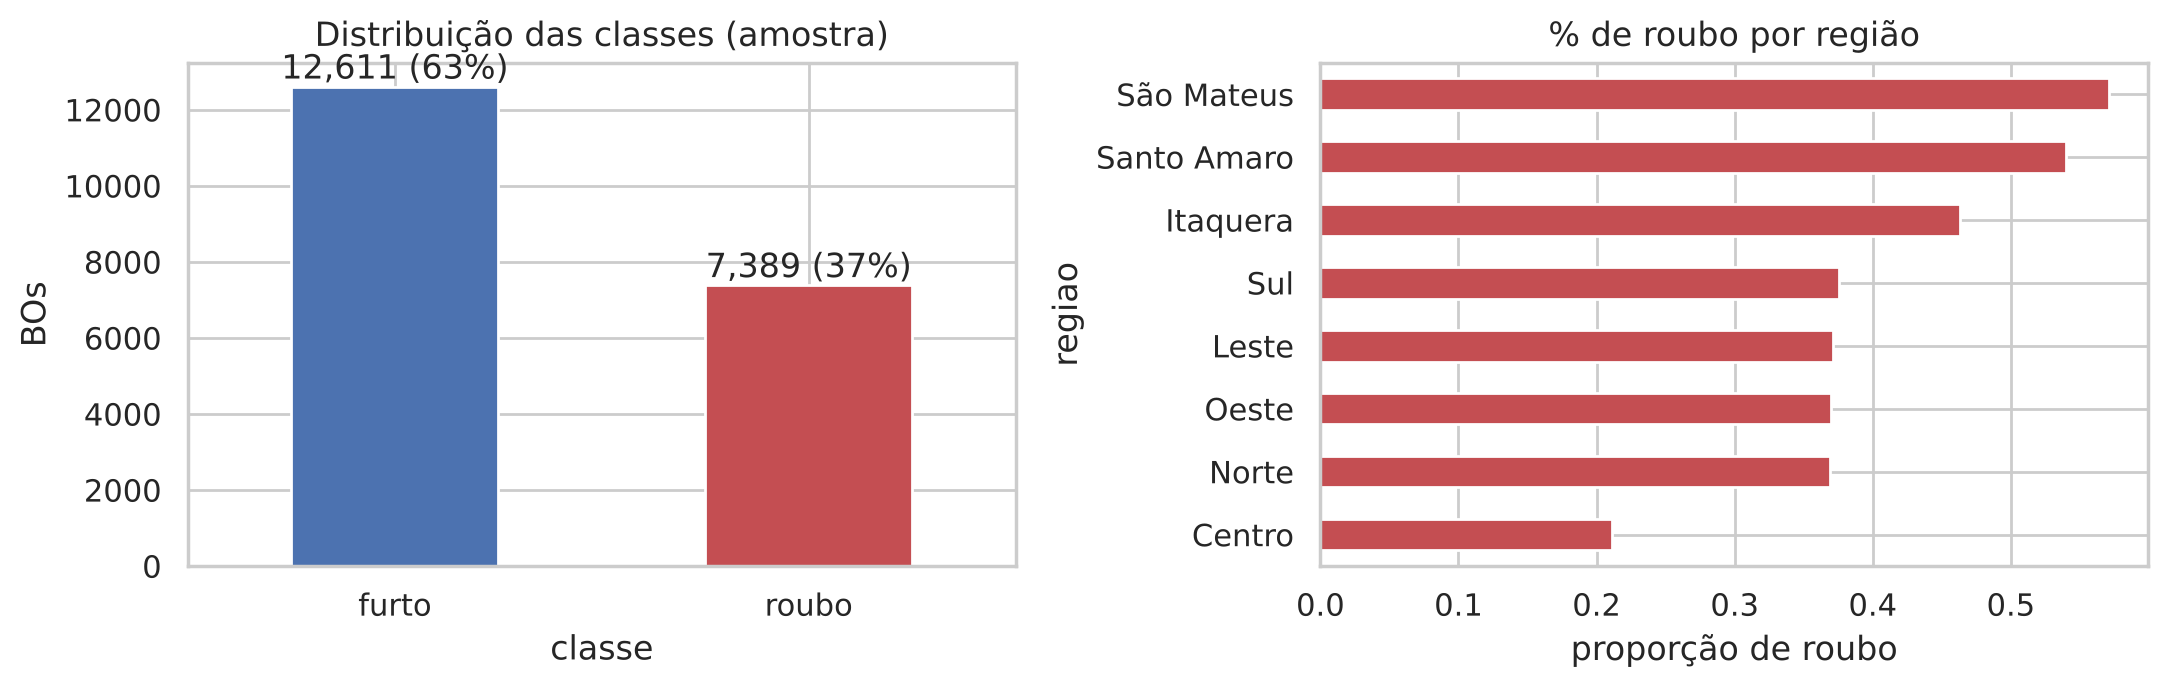

In [4]:
print("Valores ausentes por coluna:\n", dados.isna().sum().to_string())
print("\nCategorias distintas por atributo:\n", dados.nunique().to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
dados["classe"].value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_title("Distribuição das classes (amostra)"); ax[0].set_ylabel("BOs"); ax[0].tick_params(axis="x", rotation=0)
for i, v in enumerate(dados["classe"].value_counts()):
    ax[0].text(i, v, f"{v:,} ({v/len(dados):.0%})", ha="center", va="bottom")
(pd.crosstab(dados["regiao"], dados["classe"], normalize="index")["roubo"].sort_values()
   .plot.barh(ax=ax[1], color="#C44E52"))
ax[1].set_title("% de roubo por região"); ax[1].set_xlabel("proporção de roubo")
plt.tight_layout(); plt.savefig("figuras/01_classes_regiao.png", dpi=150); plt.show()

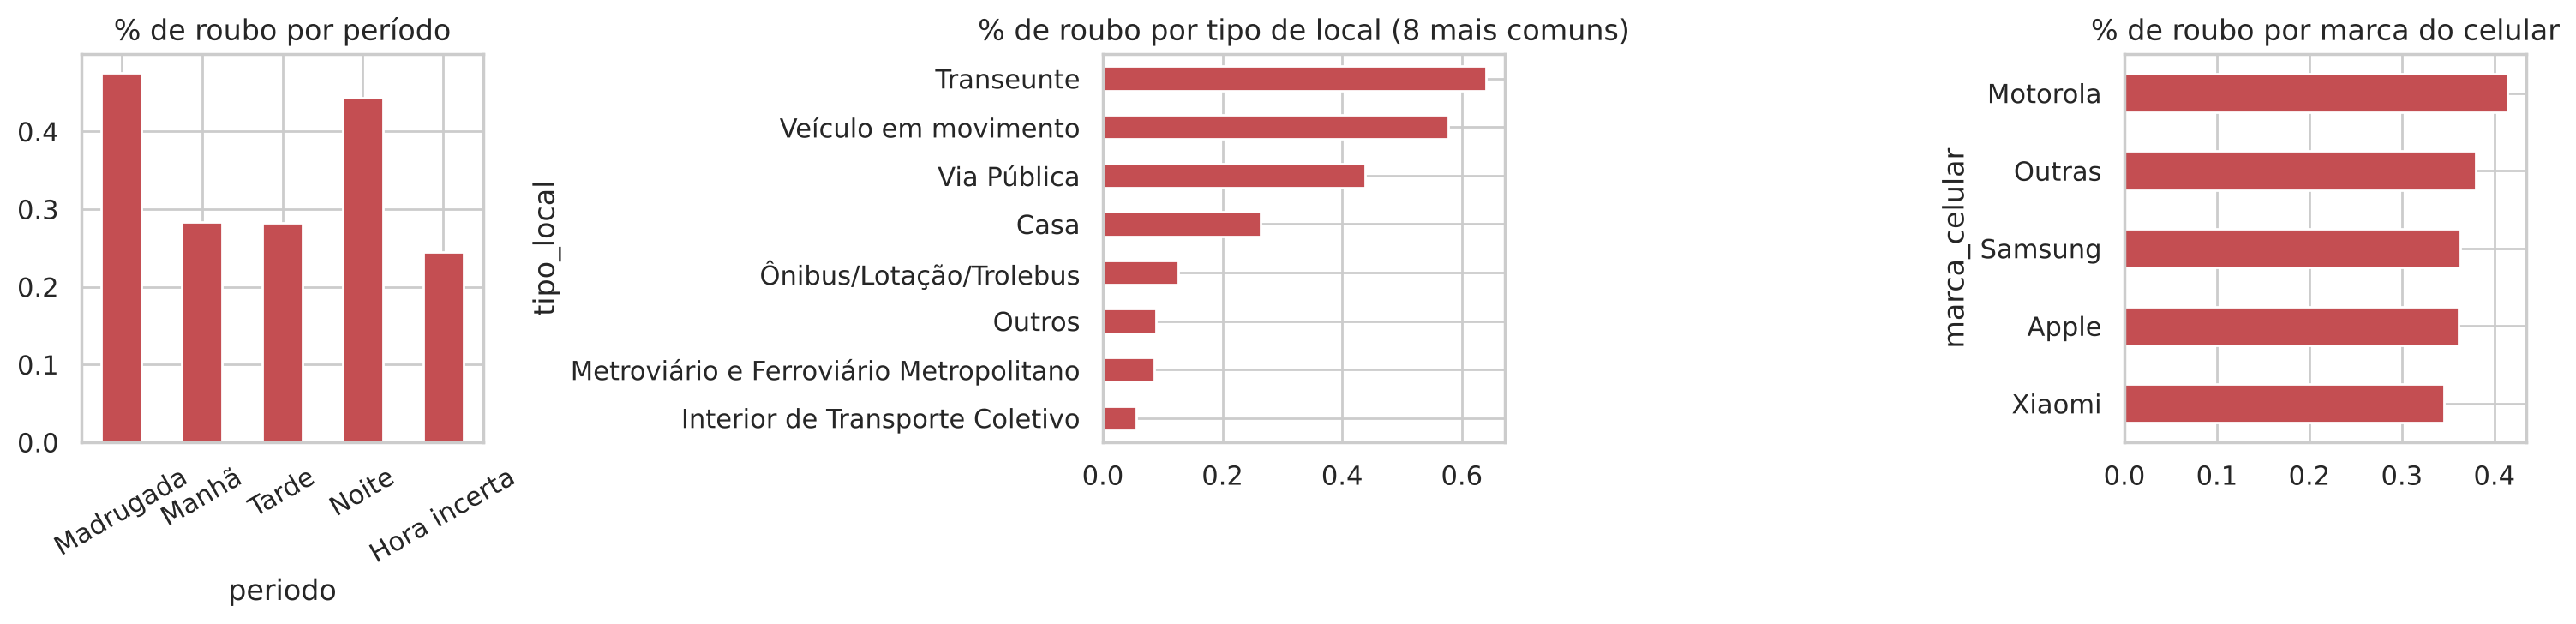

tipo_local
Via Pública                                15125
Metroviário e Ferroviário Metropolitano     1931
Outros                                      1518
Interior de Transporte Coletivo              179
Transeunte                                   175
Casa                                         159
Veículo em movimento                          97
Ônibus/Lotação/Trolebus                       95
Interior de Veículo Particular                71
Lojas                                         36
Bar/Botequim                                  34
Garagem ou abrigo de residência               30


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ordem_periodo = ["Madrugada", "Manhã", "Tarde", "Noite", "Hora incerta"]
pd.crosstab(dados["periodo"], dados["classe"], normalize="index").loc[ordem_periodo, "roubo"].plot.bar(ax=ax[0], color="#C44E52")
ax[0].set_title("% de roubo por período"); ax[0].tick_params(axis="x", rotation=30)
top_locais = dados["tipo_local"].value_counts().head(8).index
pd.crosstab(dados.loc[dados.tipo_local.isin(top_locais), "tipo_local"], dados["classe"], normalize="index")["roubo"].sort_values().plot.barh(ax=ax[1], color="#C44E52")
ax[1].set_title("% de roubo por tipo de local (8 mais comuns)")
pd.crosstab(dados["marca_celular"], dados["classe"], normalize="index")["roubo"].sort_values().plot.barh(ax=ax[2], color="#C44E52")
ax[2].set_title("% de roubo por marca do celular")
plt.tight_layout(); plt.savefig("figuras/02_exploracao_atributos.png", dpi=150); plt.show()

print(dados["tipo_local"].value_counts().head(12).to_string())

**Leitura da exploração**
- Classes **desbalanceadas** (≈63% furto × 37% roubo): por isso comparamos modelos também por **precision, recall e F1** da classe roubo,
  e usamos `class_weight` no treinamento para a rede não "chutar furto" sempre.
- **Metrô/trem** e **interior de transporte coletivo** são quase só furto; **via pública** fica perto de 50/50 — o caso mais difícil.
- A **região** separa bem: Centro tem muito mais furto; São Mateus e Santo Amaro, mais roubo.
- Não há valores ausentes no CSV: os `NULL` da planilha viraram categorias explícitas ("Não informado", "Hora incerta") no preparo.

## 3. Pré-processamento

1. **Divisão primeiro** (para o teste não influenciar nada): 70% treino · 15% validação · 15% teste, **estratificada** pela classe.
2. **Agrupamento de categorias raras** — calculado **só no treino**: mantemos os **40 bairros** mais frequentes (o resto vira `OUTRO`) e
   os tipos de local com ≥ 30 ocorrências (o resto vira `Outros`). Isso reduz ruído e mantém o formulário da aplicação utilizável.
3. **Codificação One-Hot** (`OneHotEncoder`, ajustado só no treino, `handle_unknown="ignore"`): cada categoria vira uma coluna 0/1.
   É a forma correta para atributos **nominais** — usar números (1, 2, 3…) inventaria uma ordem que não existe.
4. **Escalonamento:** **não é necessário** — todas as entradas já estão na mesma escala {0, 1}. (Se tivéssemos atributos numéricos contínuos,
   usaríamos `StandardScaler` ajustado no treino.)

In [6]:
X = dados.drop(columns="classe")
y = (dados["classe"] == "roubo").astype("float32").values   # 1 = roubo, 0 = furto

X_treino, X_tmp, y_treino, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEMENTE)
X_val, X_teste, y_val, y_teste = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEMENTE)
print(f"Treino: {len(X_treino):,} | Validação: {len(X_val):,} | Teste: {len(X_teste):,}")
print(f"% roubo -> treino {y_treino.mean():.3f} | validação {y_val.mean():.3f} | teste {y_teste.mean():.3f}")

# Agrupamento de categorias raras: definido SOMENTE com o treino
N_BAIRROS = 40
BAIRROS_MANTIDOS = X_treino["bairro"].value_counts().head(N_BAIRROS).index.tolist()
cont_local = X_treino["tipo_local"].value_counts()
LOCAIS_MANTIDOS = cont_local[cont_local >= 30].index.tolist()

def agrupar(df):
    df = df.copy()
    df["bairro"] = df["bairro"].where(df["bairro"].isin(BAIRROS_MANTIDOS), "OUTRO")
    df["tipo_local"] = df["tipo_local"].where(df["tipo_local"].isin(LOCAIS_MANTIDOS), "Outros")
    return df

COLUNAS = ["regiao", "bairro", "tipo_local", "periodo", "dia_semana", "marca_celular"]
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
encoder.fit(agrupar(X_treino)[COLUNAS])

Xtr = np.asarray(encoder.transform(agrupar(X_treino)[COLUNAS]), dtype=np.float32)
Xva = np.asarray(encoder.transform(agrupar(X_val)[COLUNAS]), dtype=np.float32)
Xte = np.asarray(encoder.transform(agrupar(X_teste)[COLUNAS]), dtype=np.float32)
N_ENTRADAS = Xtr.shape[1]

print(f"\nEntradas da MLP após One-Hot: {N_ENTRADAS}")
for col, cats in zip(COLUNAS, encoder.categories_):
    print(f"  {col:14s}: {len(cats):3d} categorias")
print("\nTipos de local mantidos:", LOCAIS_MANTIDOS)

Treino: 14,000 | Validação: 3,000 | Teste: 3,000
% roubo -> treino 0.369 | validação 0.370 | teste 0.369

Entradas da MLP após One-Hot: 75
  regiao        :   8 categorias
  bairro        :  41 categorias
  tipo_local    :   9 categorias
  periodo       :   5 categorias
  dia_semana    :   7 categorias
  marca_celular :   5 categorias

Tipos de local mantidos: ['Via Pública', 'Metroviário e Ferroviário Metropolitano', 'Outros', 'Interior de Transporte Coletivo', 'Casa', 'Transeunte', 'Veículo em movimento', 'Ônibus/Lotação/Trolebus', 'Interior de Veículo Particular']


In [7]:
# Peso das classes: compensa o desbalanceamento (cada erro em 'roubo' pesa ~1,7x)
peso_classes = {0: 1.0, 1: float((y_treino == 0).sum() / (y_treino == 1).sum())}
print("class_weight:", peso_classes)

# Linha de base simples (não é MLP): regressão logística — serve para saber se a rede agrega algo
base = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xtr, y_treino)
p = base.predict(Xva)
print(f"Regressão logística (validação): acurácia={accuracy_score(y_val, p):.3f} | F1 roubo={f1_score(y_val, p):.3f}")

class_weight: {0: 1.0, 1: 1.7068832173240527}
Regressão logística (validação): acurácia=0.666 | F1 roubo=0.623


## 4. Implementação da MLP e configuração do treinamento

Arquitetura (todas as variantes seguem este molde, com `tf.keras.Sequential`):

```
Entrada (75 neurônios = colunas One-Hot)
   → Dense(n₁, ReLU) [→ Dropout]   ← camadas ocultas densas
   → Dense(n₂, ReLU) [→ Dropout]
   → Dense(1, Sigmoid)              ← saída binária: P(roubo)
```

**Como a rede funciona:** cada neurônio calcula uma soma ponderada das entradas mais um viés (`z = W·x + b`) e aplica
uma ativação. As camadas ocultas aprendem **combinações** de atributos (ex.: *via pública + madrugada + zona leste*),
que um modelo linear não captura. A saída devolve a probabilidade de roubo; P(furto) = 1 − P(roubo).

| Escolha | Valor | Justificativa |
|---|---|---|
| Ativação oculta | **ReLU** | Simples, rápida, evita o *vanishing gradient* da sigmoid em camadas internas. |
| Ativação de saída | **Sigmoid** (1 neurônio) | Problema **binário**: devolve um valor entre 0 e 1, interpretado como P(roubo). |
| Função de perda | **Binary cross-entropy** | Perda padrão para saída sigmoid; penaliza forte quando a rede está confiante e errada. |
| Otimizador | **Adam** | Ajusta a taxa de aprendizado por peso; converge bem sem muito ajuste. |
| Taxa de aprendizado | 0,001 (padrão) / 0,0005 (modelo 4) | Valor menor deixa o treino mais estável quando há regularização. |
| Batch size | **64** | Compromisso entre estabilidade do gradiente e velocidade em 14 mil exemplos. |
| Épocas | 30–80 (com *EarlyStopping* nos modelos regularizados) | Para quando a perda de validação para de melhorar por 8 épocas e restaura os melhores pesos. |
| Limiar de decisão | 0,5 | P(roubo) ≥ 0,5 → roubo. |

In [8]:
def criar_mlp(camadas, dropout=0.0, l2=0.0, taxa_aprendizado=1e-3, nome="mlp"):
    modelo = tf.keras.Sequential(name=nome)
    modelo.add(tf.keras.Input(shape=(N_ENTRADAS,)))
    for i, neuronios in enumerate(camadas):
        modelo.add(tf.keras.layers.Dense(
            neuronios, activation="relu", name=f"oculta_{i+1}",
            kernel_regularizer=tf.keras.regularizers.l2(l2) if l2 else None))
        if dropout:
            modelo.add(tf.keras.layers.Dropout(dropout, name=f"dropout_{i+1}"))
    modelo.add(tf.keras.layers.Dense(1, activation="sigmoid", name="saida"))
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=taxa_aprendizado),
                   loss="binary_crossentropy", metrics=["accuracy"])
    return modelo

criar_mlp([64, 32], dropout=0.3, nome="exemplo").summary()

Model: "exemplo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 64)             │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,977 (27.25 KB)

 Trainable params: 6,977 (27.25 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Experimentos com arquiteturas

Treinamos **4 configurações**, mudando uma ideia por vez:

| # | Nome | Camadas ocultas | Regularização | LR | Épocas | O que queremos testar |
|---|---|---|---|---|---|---|
| 1 | **Rasa** | 16 | — | 0,001 | 30 | Uma única camada pequena já resolve? (ponto de partida) |
| 2 | **Média + Dropout** | 64 → 32 | Dropout 0,3 + EarlyStopping | 0,001 | até 60 | Mais capacidade, com freio contra overfitting. |
| 3 | **Profunda sem regularização** | 256 → 128 → 64 | — | 0,001 | 60 | O que acontece com muita capacidade e nenhum freio? |
| 4 | **Média + Dropout + L2 + LR menor** | 64 → 32 | Dropout 0,3 + L2 1e-4 + EarlyStopping | 0,0005 | até 80 | Treino mais suave e pesos menores melhoram a generalização? |

In [9]:
EXPERIMENTOS = [
    dict(nome="1_Rasa",               camadas=[16],            dropout=0.0, l2=0.0,  lr=1e-3, epocas=30, early=False),
    dict(nome="2_Media_Dropout",      camadas=[64, 32],        dropout=0.3, l2=0.0,  lr=1e-3, epocas=60, early=True),
    dict(nome="3_Profunda_SemReg",    camadas=[256, 128, 64],  dropout=0.0, l2=0.0,  lr=1e-3, epocas=60, early=False),
    dict(nome="4_Media_Dropout_L2",   camadas=[64, 32],        dropout=0.3, l2=1e-4, lr=5e-4, epocas=80, early=True),
]

def metricas(y_true, prob, limiar=0.5):
    pred = (prob >= limiar).astype(int)
    return dict(acuracia=accuracy_score(y_true, pred), precision=precision_score(y_true, pred),
                recall=recall_score(y_true, pred), f1=f1_score(y_true, pred),
                f1_macro=f1_score(y_true, pred, average="macro"))

modelos, historicos, linhas = {}, {}, []
for exp in EXPERIMENTOS:
    tf.keras.utils.set_random_seed(SEMENTE)
    m = criar_mlp(exp["camadas"], exp["dropout"], exp["l2"], exp["lr"], nome=exp["nome"])
    cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)] if exp["early"] else []
    h = m.fit(Xtr, y_treino, validation_data=(Xva, y_val), epochs=exp["epocas"], batch_size=64,
              class_weight=peso_classes, callbacks=cbs, verbose=0)
    modelos[exp["nome"]], historicos[exp["nome"]] = m, h.history
    r = metricas(y_val, m.predict(Xva, verbose=0).ravel())
    r.update(modelo=exp["nome"], parametros=m.count_params(), epocas_treinadas=len(h.history["loss"]),
             loss_treino_final=h.history["loss"][-1], loss_val_final=h.history["val_loss"][-1],
             loss_val_minima=min(h.history["val_loss"]), acc_treino_final=h.history["accuracy"][-1])
    linhas.append(r)
    print(f"{exp['nome']:22s} épocas={r['epocas_treinadas']:3d}  acc_val={r['acuracia']:.3f}  F1_val={r['f1']:.3f}  "
          f"loss treino={r['loss_treino_final']:.3f}  loss val={r['loss_val_final']:.3f}")

1_Rasa                 épocas= 30  acc_val=0.667  F1_val=0.606  loss treino=0.711  loss val=0.590


2_Media_Dropout        épocas= 11  acc_val=0.672  F1_val=0.612  loss treino=0.721  loss val=0.591


3_Profunda_SemReg      épocas= 60  acc_val=0.639  F1_val=0.571  loss treino=0.443  loss val=1.911


4_Media_Dropout_L2     épocas= 15  acc_val=0.677  F1_val=0.616  loss treino=0.741  loss val=0.598


## 6. Comparação das arquiteturas (conjunto de **validação**)

In [10]:
resultados = pd.DataFrame(linhas).set_index("modelo")
cols = ["parametros", "epocas_treinadas", "acuracia", "precision", "recall", "f1", "f1_macro",
        "acc_treino_final", "loss_treino_final", "loss_val_final", "loss_val_minima"]
resultados = resultados[cols]
resultados.round(3).to_csv("modelo/resultados_validacao.csv")
display(resultados.style.format(precision=3).highlight_max(subset=["acuracia", "precision", "recall", "f1", "f1_macro"], color="#d4edda"))

,parametros,epocas_treinadas,acuracia,precision,recall,f1,f1_macro,acc_treino_final,loss_treino_final,loss_val_final,loss_val_minima
modelo,,,,,,,,,,,
1_Rasa,1233,30,0.667,0.539,0.693,0.606,0.659,0.699,0.711,0.590,0.590
2_Media_Dropout,6977,11,0.672,0.543,0.700,0.612,0.664,0.699,0.721,0.591,0.587
3_Profunda_SemReg,60673,60,0.639,0.509,0.651,0.571,0.629,0.798,0.443,1.911,0.573
4_Media_Dropout_L2,6977,15,0.677,0.550,0.701,0.616,0.669,0.693,0.741,0.598,0.597


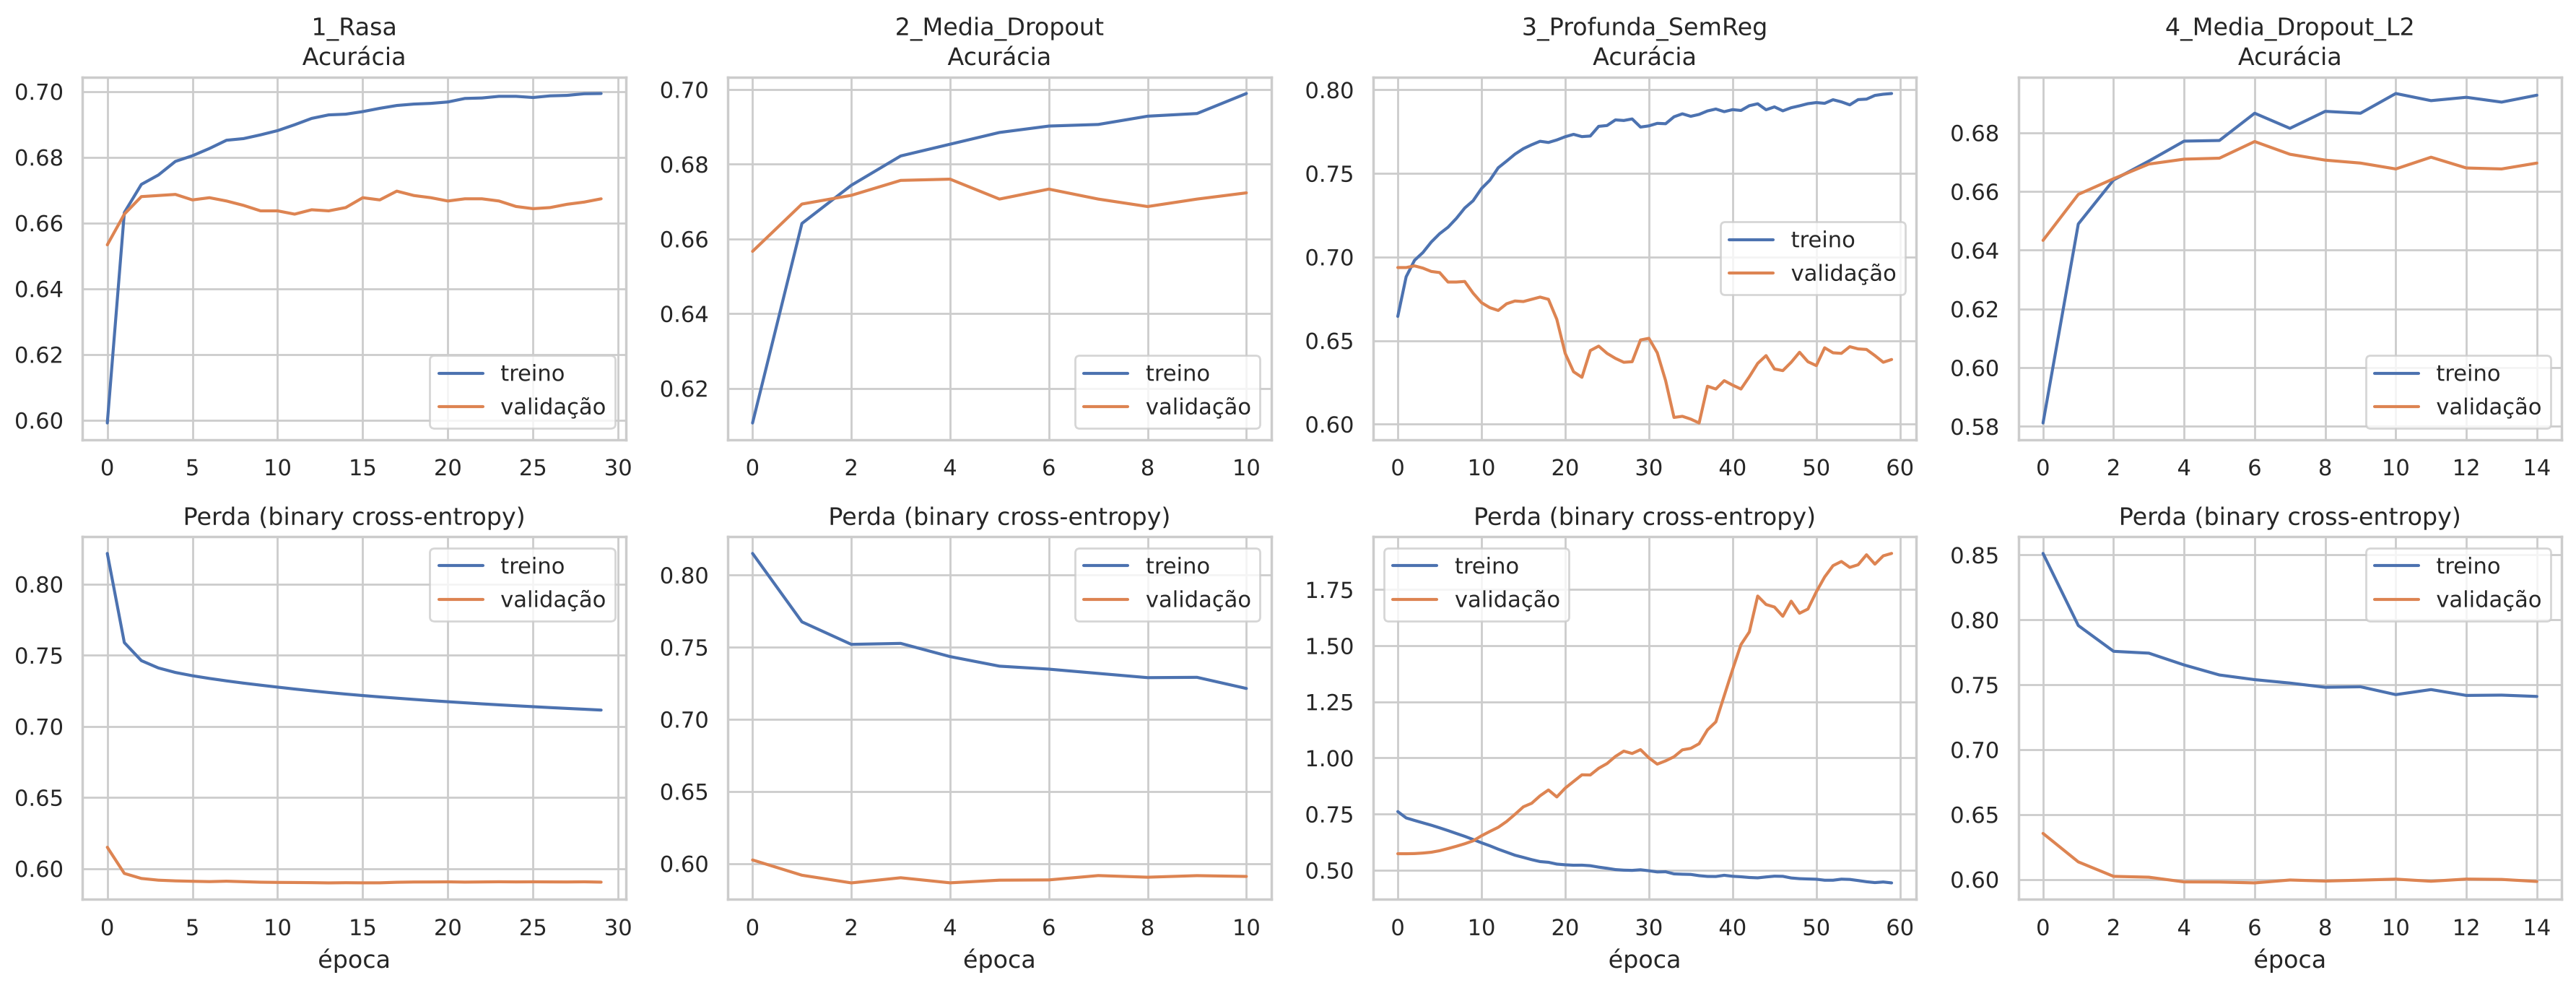

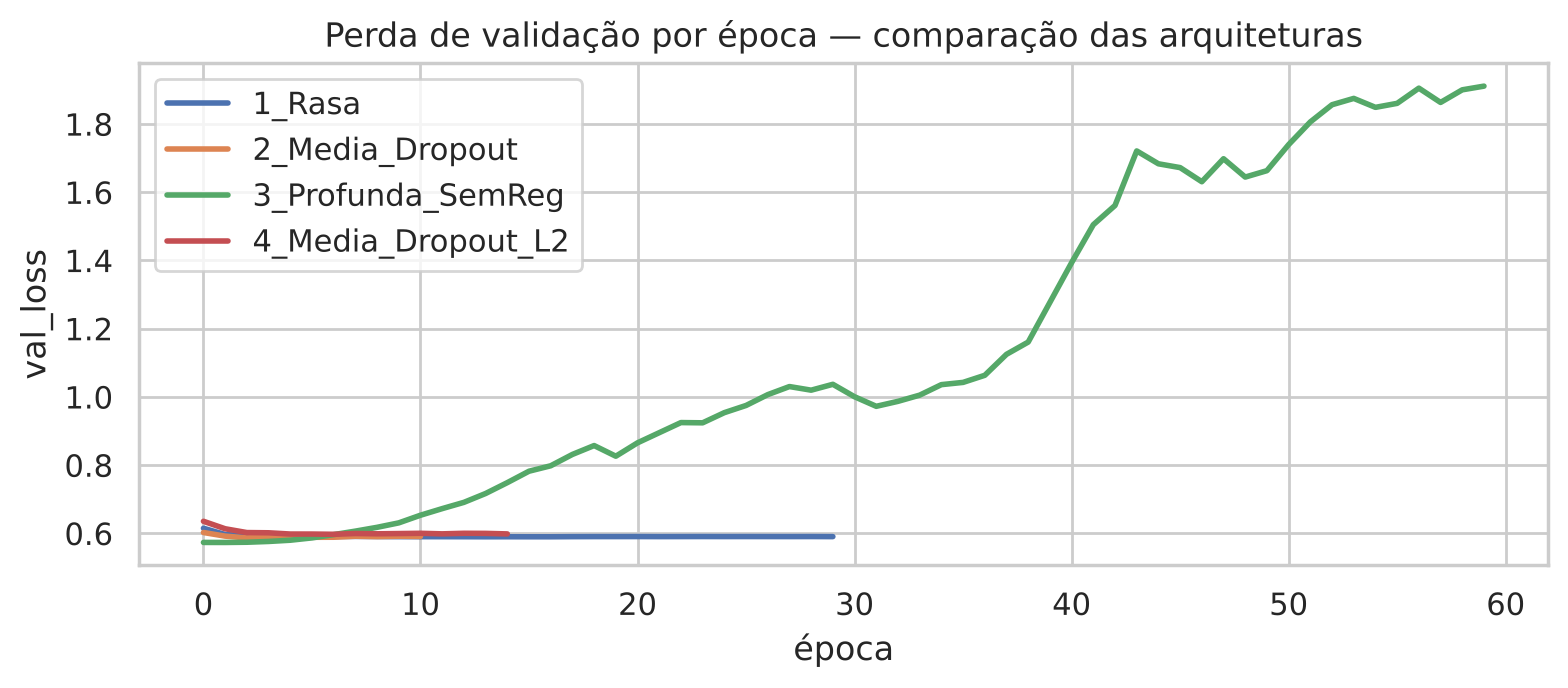

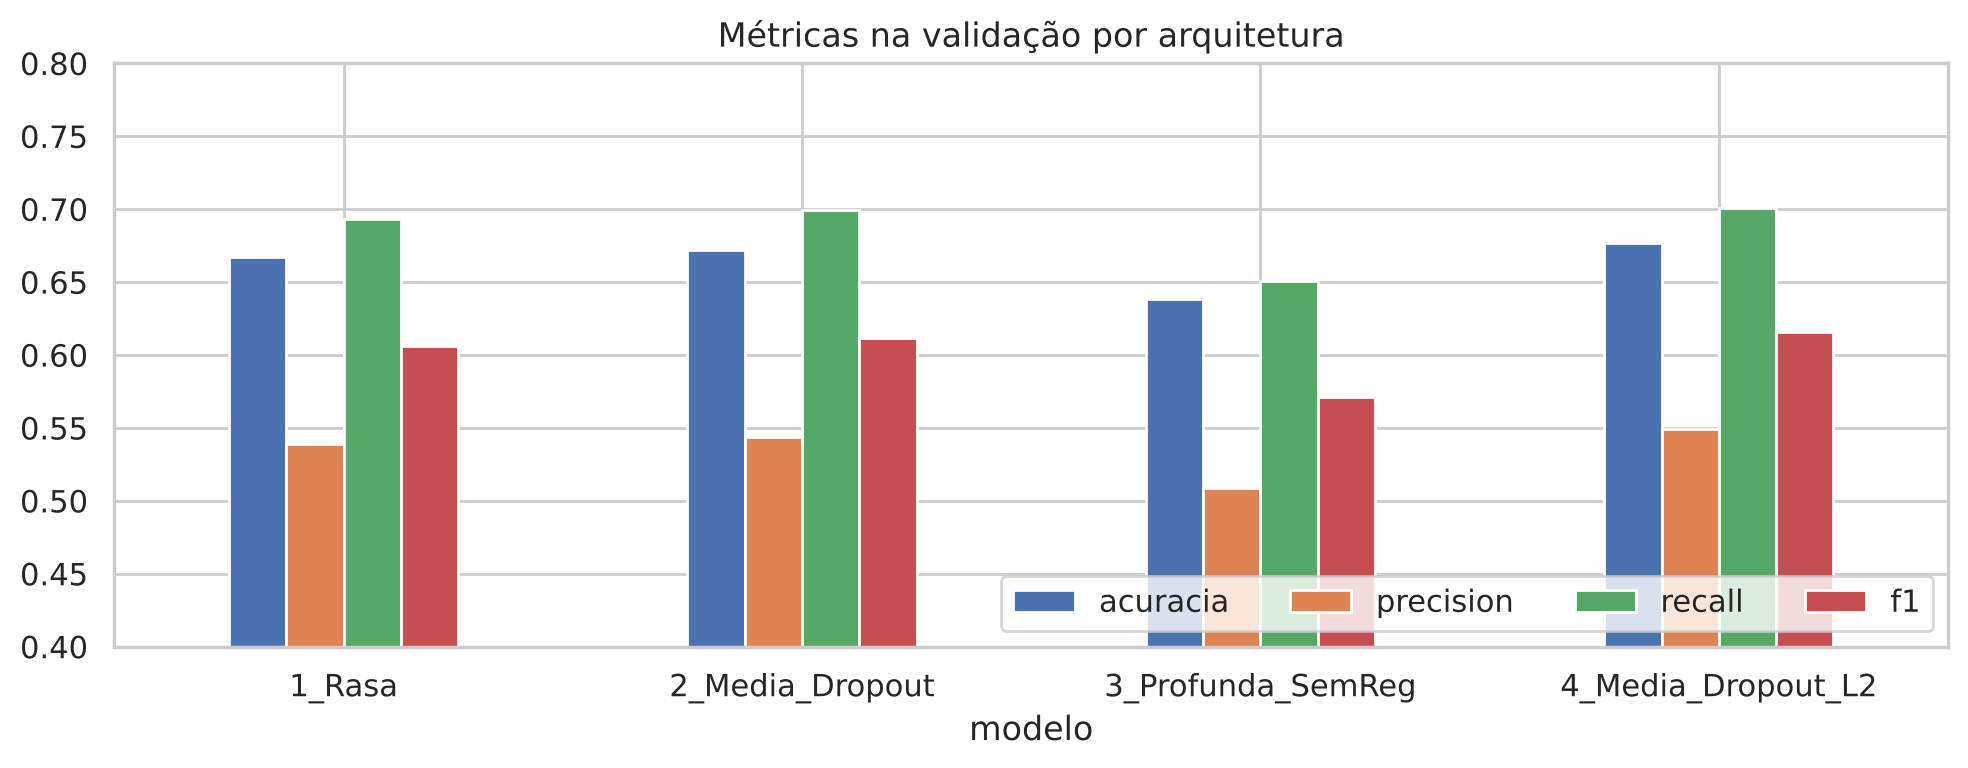

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=False)
for j, (nome, h) in enumerate(historicos.items()):
    axes[0, j].plot(h["accuracy"], label="treino"); axes[0, j].plot(h["val_accuracy"], label="validação")
    axes[0, j].set_title(f"{nome}\nAcurácia"); axes[0, j].legend()
    axes[1, j].plot(h["loss"], label="treino"); axes[1, j].plot(h["val_loss"], label="validação")
    axes[1, j].set_title("Perda (binary cross-entropy)"); axes[1, j].set_xlabel("época"); axes[1, j].legend()
plt.tight_layout(); plt.savefig("figuras/03_curvas_todos_modelos.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.6))
for nome, h in historicos.items():
    ax.plot(h["val_loss"], label=nome, lw=2)
ax.set_title("Perda de validação por época — comparação das arquiteturas"); ax.set_xlabel("época"); ax.set_ylabel("val_loss"); ax.legend()
plt.tight_layout(); plt.savefig("figuras/06_val_loss_comparacao.png", dpi=150); plt.show()

ax = resultados[["acuracia", "precision", "recall", "f1"]].plot.bar(figsize=(10, 4), rot=0, ylim=(0.4, 0.8))
ax.set_title("Métricas na validação por arquitetura"); ax.legend(loc="lower right", ncol=4)
plt.tight_layout(); plt.savefig("figuras/04_comparacao_metricas.png", dpi=150); plt.show()

### Critério de seleção
Escolhemos pela **validação** (o teste fica guardado), usando o **F1-score da classe roubo** como critério principal:
ele equilibra *precision* (quando a rede diz "roubo", acerta?) e *recall* (dos roubos reais, quantos ela encontra?), o que importa
mais que a acurácia numa base desbalanceada — um modelo que dissesse sempre "furto" teria 63% de acurácia e seria inútil.
Em caso de empate exato, preferimos o modelo com **menor diferença de acurácia treino × validação** (mais estável).

> Obs.: não usamos a *perda* de validação para desempatar porque, no modelo com L2, o Keras soma a penalidade dos pesos à perda,
> o que deixa os valores de perda não comparáveis entre arquiteturas.

In [12]:
gap = resultados["acc_treino_final"] - resultados["acuracia"]
ESCOLHIDO = (resultados.assign(gap=gap).sort_values(["f1", "gap"], ascending=[False, True]).index[0])
modelo_final = modelos[ESCOLHIDO]
print("Arquitetura escolhida:", ESCOLHIDO)
print(resultados.loc[ESCOLHIDO, ["acuracia", "precision", "recall", "f1", "f1_macro"]].round(3).to_string())
modelo_final.summary()

Arquitetura escolhida: 4_Media_Dropout_L2
acuracia     0.677
precision    0.550
recall       0.701
f1           0.616
f1_macro     0.669


Model: "4_Media_Dropout_L2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 64)             │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,933 (81.77 KB)

 Trainable params: 6,977 (27.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 13,956 (54.52 KB)

## 7. Avaliação final no conjunto de **teste** (usado uma única vez)

Desempenho no TESTE: {'acuracia': 0.684, 'precision': 0.556, 'recall': 0.723, 'f1': 0.628, 'f1_macro': 0.677}

              precision    recall  f1-score   support

       furto      0.803     0.662     0.726      1892
       roubo      0.556     0.723     0.628      1108

    accuracy                          0.684      3000
   macro avg      0.679     0.692     0.677      3000
weighted avg      0.712     0.684     0.690      3000

Comparação com a linha de base (regressão logística) no teste: {'acuracia': 0.671, 'precision': 0.538, 'recall': 0.768, 'f1': 0.633, 'f1_macro': 0.667}


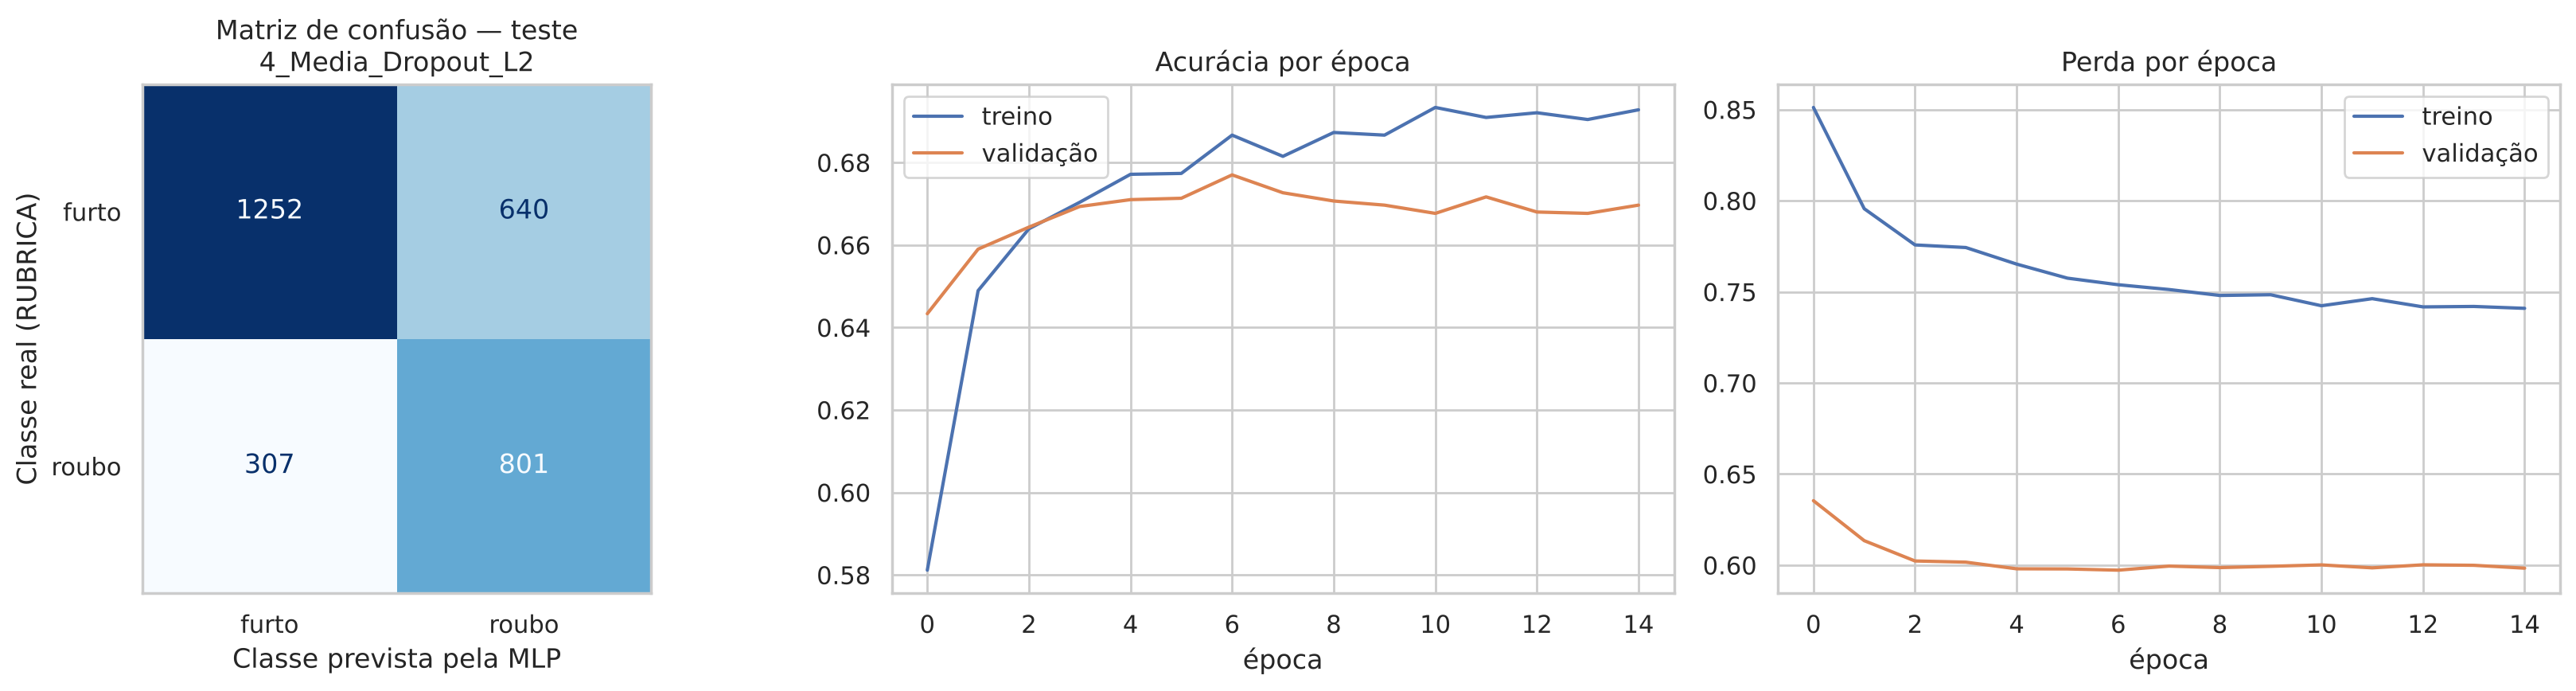

In [13]:
prob_teste = modelo_final.predict(Xte, verbose=0).ravel()
pred_teste = (prob_teste >= 0.5).astype(int)
final = metricas(y_teste, prob_teste)
print("Desempenho no TESTE:", {k: round(v, 3) for k, v in final.items()})
print()
print(classification_report(y_teste, pred_teste, target_names=["furto", "roubo"], digits=3))

prob_base = base.predict_proba(Xte)[:, 1]
print("Comparação com a linha de base (regressão logística) no teste:",
      {k: round(v, 3) for k, v in metricas(y_teste, prob_base).items()})

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_teste, pred_teste), display_labels=["furto", "roubo"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title(f"Matriz de confusão — teste\n{ESCOLHIDO}"); ax[0].grid(False)
ax[0].set_xlabel("Classe prevista pela MLP"); ax[0].set_ylabel("Classe real (RUBRICA)")
h = historicos[ESCOLHIDO]
ax[1].plot(h["accuracy"], label="treino"); ax[1].plot(h["val_accuracy"], label="validação"); ax[1].set_title("Acurácia por época"); ax[1].set_xlabel("época"); ax[1].legend()
ax[2].plot(h["loss"], label="treino"); ax[2].plot(h["val_loss"], label="validação"); ax[2].set_title("Perda por época"); ax[2].set_xlabel("época"); ax[2].legend()
plt.tight_layout(); plt.savefig("figuras/05_modelo_escolhido_teste.png", dpi=150); plt.show()

pd.DataFrame([final], index=[ESCOLHIDO]).round(3).to_csv("modelo/resultado_teste.csv")

In [14]:
# Diagnóstico de overfitting / underfitting de cada arquitetura
for nome, h in historicos.items():
    gap_acc = h["accuracy"][-1] - h["val_accuracy"][-1]
    subida_val = h["val_loss"][-1] - min(h["val_loss"])
    if subida_val > 0.05 or gap_acc > 0.05:
        diag = "OVERFITTING: treino continua melhorando e a validação piora"
    elif h["accuracy"][-1] < 0.66 and h["val_accuracy"][-1] < 0.66:
        diag = "possível underfitting / limite dos atributos"
    else:
        diag = "ajuste equilibrado (curvas próximas)"
    print(f"{nome:22s} gap acc treino-val={gap_acc:+.3f} | val_loss final - mínima={subida_val:+.3f} -> {diag}")

1_Rasa                 gap acc treino-val=+0.032 | val_loss final - mínima=+0.001 -> ajuste equilibrado (curvas próximas)
2_Media_Dropout        gap acc treino-val=+0.027 | val_loss final - mínima=+0.004 -> ajuste equilibrado (curvas próximas)
3_Profunda_SemReg      gap acc treino-val=+0.159 | val_loss final - mínima=+1.338 -> OVERFITTING: treino continua melhorando e a validação piora
4_Media_Dropout_L2     gap acc treino-val=+0.023 | val_loss final - mínima=+0.001 -> ajuste equilibrado (curvas próximas)


### Análise
- **Modelo 3 (Profunda sem regularização)** é o caso clássico de **overfitting**: a acurácia de treino sobe sem parar, enquanto a
  perda de validação atinge o mínimo cedo e depois **dispara** — a rede decora combinações raras do treino.
- **Modelos 2 e 4** (Dropout, L2 e EarlyStopping) mantêm treino e validação próximos: o *EarlyStopping* interrompe o treino quando a
  validação para de melhorar e restaura os melhores pesos.
- O **teto de ~70% de acurácia** não é falta de capacidade da rede (a profunda até piora): é **limite da informação** nos atributos.
  Em via pública — 3/4 da base — roubo e furto ficam perto de 50/50 com os mesmos bairro, período e aparelho.
  Isso é um **underfitting causado pelos dados**, não pela arquitetura.
- Nos modelos 1, 2 e 4 a **perda de treino fica acima da de validação**. Isso não é erro: no treino a perda é calculada com
  `class_weight` (erros em roubo pesam 1,7×) e com Dropout/L2 ativos; na validação, não.
- **Comparação com a linha de base (teste):** a MLP escolhida tem acurácia e F1-macro um pouco maiores que a regressão logística
  (0,684 × 0,671 e 0,677 × 0,667), com F1 de roubo praticamente igual (0,628 × 0,633). Ou seja, a maior parte do sinal é "aditiva"
  (região, tipo de local, período) e a rede ganha pouco com interações — mais uma evidência de que o limite está nos atributos.

## 8. Exportação do modelo para a aplicação web

In [15]:
modelo_final.save("modelo/mlp_roubo_furto.keras")

# Pesos das camadas densas (Dropout não atua na inferência) + vocabulário do One-Hot.
camadas_densas = [l for l in modelo_final.layers if isinstance(l, tf.keras.layers.Dense)]
bairro_regiao = (agrupar(X_treino).query("bairro != 'OUTRO'").groupby("bairro")["regiao"]
                 .agg(lambda s: s.value_counts().index[0]).to_dict())
exportacao = {
    "modelo": ESCOLHIDO,
    "fonte": "SSP-SP - Celulares subtraídos 2025 (https://www.ssp.sp.gov.br/estatistica/consultas)",
    "colunas": COLUNAS,
    "categorias": {c: [str(v) for v in cats] for c, cats in zip(COLUNAS, encoder.categories_)},
    "bairro_regiao": bairro_regiao,
    "camadas": [{"W": l.get_weights()[0].round(6).tolist(), "b": l.get_weights()[1].round(6).tolist(),
                 "ativacao": l.get_config()["activation"]} for l in camadas_densas],
    "metricas_teste": {k: round(float(v), 4) for k, v in final.items()},
    "metricas_validacao": resultados.round(4).reset_index().to_dict(orient="records"),
}
Path("docs").mkdir(exist_ok=True)
with open("docs/modelo.json", "w", encoding="utf-8") as f:
    json.dump(exportacao, f, ensure_ascii=False)
with open("modelo/preprocessamento.json", "w", encoding="utf-8") as f:
    json.dump({k: exportacao[k] for k in ["colunas", "categorias", "bairro_regiao"]}, f, ensure_ascii=False, indent=1)

# Conferência: a rede reimplementada em NumPy (igual ao JavaScript da página) dá o mesmo resultado que o Keras
def prever_numpy(x):
    a = x
    for c in exportacao["camadas"]:
        a = a @ np.array(c["W"]) + np.array(c["b"])
        a = np.maximum(a, 0) if c["ativacao"] == "relu" else 1 / (1 + np.exp(-a))
    return a.ravel()
dif = np.abs(prever_numpy(Xte[:500]) - prob_teste[:500]).max()
print(f"Diferença máxima Keras x reimplementação: {dif:.2e}")

# Gera a aplicação web (docs/index.html) com os pesos embutidos
if Path("gerar_app.py").exists() and Path("app/template.html").exists():
    import gerar_app
else:
    print("gerar_app.py/app/template.html não encontrados: docs/modelo.json foi salvo, mas a página não foi regenerada.")

Diferença máxima Keras x reimplementação: 1.03e-06
docs/index.html gerado (163 KB)


In [16]:
# Exemplo de uso: uma ocorrência hipotética
exemplo = pd.DataFrame([dict(regiao="Oeste", bairro="PINHEIROS", tipo_local="Via Pública",
                             periodo="Noite", dia_semana="Sexta", marca_celular="Apple")])
p_roubo = float(modelo_final.predict(np.asarray(encoder.transform(agrupar(exemplo)[COLUNAS]), dtype=np.float32), verbose=0)[0, 0])
print(f"Roubo = {p_roubo:.0%} | Furto = {1 - p_roubo:.0%}")
print("Interpretação correta: considerando que a ocorrência ACONTECEU com essas características, o modelo atribui essas "
      "probabilidades a cada tipo. NÃO é a chance de acontecer um crime em Pinheiros numa sexta à noite.")

Roubo = 59% | Furto = 41%
Interpretação correta: considerando que a ocorrência ACONTECEU com essas características, o modelo atribui essas probabilidades a cada tipo. NÃO é a chance de acontecer um crime em Pinheiros numa sexta à noite.


## 9. Conclusões e limitações

**Conclusões**
- Foram treinadas e comparadas **4 arquiteturas de MLP**; a escolha foi feita pela **validação** e confirmada uma única vez no **teste**.
- A rede aprendeu padrões coerentes com a realidade: transporte público (metrô/trem/ônibus) e o Centro puxam para **furto**;
  via pública na periferia, madrugada/noite e veículo em movimento puxam para **roubo**.
- Mais camadas/neurônios **não** melhoraram o resultado — pioraram (overfitting). Regularização e parada antecipada foram decisivas.

**Limitações**
- A base é **bruta** e não é estatística oficial (aviso da própria SSP); há variação de grafia, campos `NULL` e dois sistemas (R.D.O./S.P.J.)
  com campos diferentes para horário.
- Só cobre **celulares**. Outros objetos ou crimes podem ter padrões diferentes.
- Os atributos disponíveis antes de saber a natureza do crime são pobres para separar roubo de furto em **via pública** — daí o teto de ~70%.
- Registro depende de a vítima fazer o BO: furtos "sem importância" e roubos por medo de represália podem estar sub-registrados.
- O modelo descreve **o tipo** de uma ocorrência, **não** prevê crimes nem deve orientar decisões sobre pessoas ou lugares.